Starting training...
Epoch  30/150 | Avg Loss: 0.002845
Epoch  60/150 | Avg Loss: 0.000647
Epoch  90/150 | Avg Loss: 0.000534
Epoch 120/150 | Avg Loss: 0.000140
Epoch 150/150 | Avg Loss: 0.000340


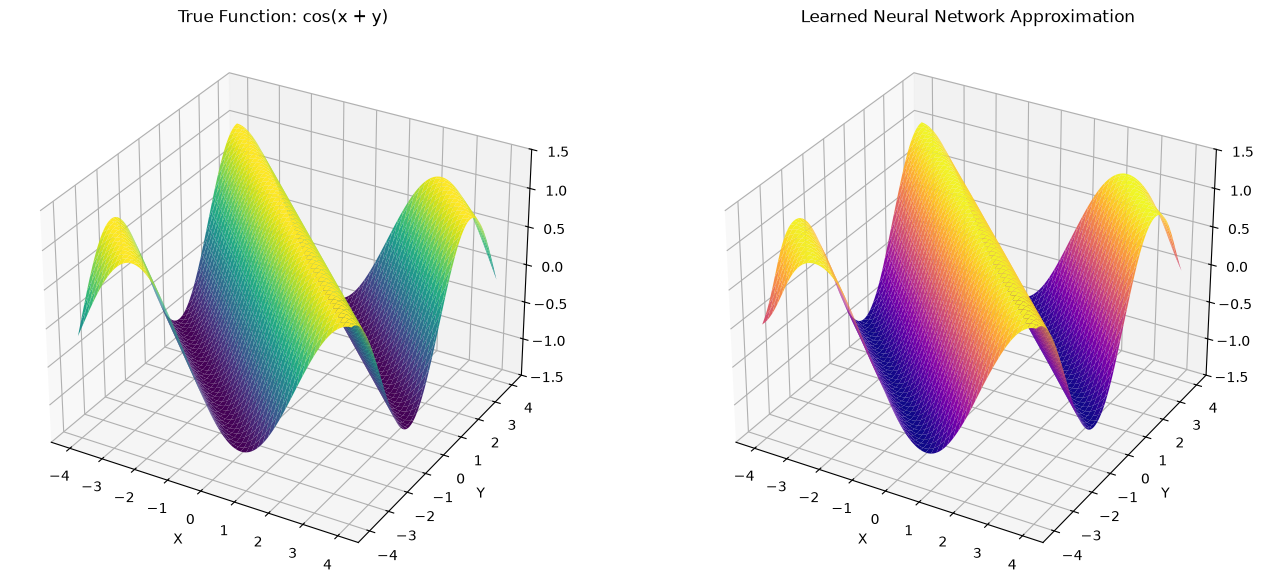

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

# ==========================================
# 1. Generate the Discretized Dataset
# ==========================================
# Create a 100x100 grid spanning [-4, 4] for both x and y
grid_size = 100
x = torch.linspace(-4, 4, grid_size)
y = torch.linspace(-4, 4, grid_size)
X, Y = torch.meshgrid(x, y, indexing='ij')

# Flatten into (10000, 2) input tensor and (10000, 1) target tensor
inputs = torch.stack([X.flatten(), Y.flatten()], dim=1)
targets = torch.cos(inputs[:, 0] + inputs[:, 1]).unsqueeze(1)

# Package into a DataLoader for mini-batch gradient descent
dataset = TensorDataset(inputs, targets)
dataloader = DataLoader(dataset, batch_size=256, shuffle=True)

# ==========================================
# 2. Define the Neural Network Architecture
# ==========================================
class CosNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 64),
            nn.Tanh(),        # Tanh is ideal for smooth periodic functions
            nn.Linear(64, 64),
            nn.Tanh(),
            nn.Linear(64, 1)  # Single scalar output
        )

    def forward(self, x):
        return self.net(x)

model = CosNet()

# ==========================================
# 3. Setup Loss and Optimizer
# ==========================================
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.005)

# ==========================================
# 4. Training Loop
# ==========================================
epochs = 150
print("Starting training...")
for epoch in range(epochs):
    epoch_loss = 0.0
    for batch_inputs, batch_targets in dataloader:
        optimizer.zero_grad()
        predictions = model(batch_inputs)
        loss = criterion(predictions, batch_targets)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()

    if (epoch + 1) % 30 == 0:
        print(f"Epoch {epoch+1:3d}/{epochs} | Avg Loss: {epoch_loss/len(dataloader):.6f}")

# ==========================================
# 5. Evaluate and Visualize Results
# ==========================================
model.eval()
with torch.no_grad():
    predictions = model(inputs).reshape(grid_size, grid_size)

# Plotting the True vs Learned Function
fig = plt.figure(figsize=(14, 6))

# True Function Plot
ax1 = fig.add_subplot(121, projection='3d')
ax1.plot_surface(X.numpy(), Y.numpy(), targets.reshape(grid_size, grid_size).numpy(), cmap='viridis')
ax1.set_title("True Function: cos(x + y)")
ax1.set_xlabel("X")
ax1.set_ylabel("Y")
ax1.set_zlim(-1.5, 1.5)

# Learned Function Plot
ax2 = fig.add_subplot(122, projection='3d')
ax2.plot_surface(X.numpy(), Y.numpy(), predictions.numpy(), cmap='plasma')
ax2.set_title("Learned Neural Network Approximation")
ax2.set_xlabel("X")
ax2.set_ylabel("Y")
ax2.set_zlim(-1.5, 1.5)

plt.tight_layout()
plt.show()